# 01 · População

Humanos (P31=Q5) com cidadania brasileira (P27=Q155) e artigo na Wikipédia em português, segundo o Wikidata. Os dados são gerados por `scripts/populacao.py` (`make populacao`). Este notebook só lê `data/processed/populacao.csv` e faz tabelas e gráficos.

In [1]:
import sys; sys.path.insert(0, '../scripts')
import matplotlib.pyplot as plt
import analise_populacao as ap
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
F_COR, M_COR = '#b5367a', '#3b6fb6'
df = ap.carregar()
print(f'{len(df):,} pessoas'.replace(',', '.'))

45.788 pessoas


## Total por sexo (P21)

`multiplo` = mais de um valor em P21; `outro` = valores fora de feminino e masculino (mulher trans, não binário etc.).

In [2]:
ap.por_sexo(df)

,n,%
sexo,,
M,36116,78.88
F,9281,20.27
sem_dado,204,0.45
outro,161,0.35
multiplo,26,0.06


## % de mulheres por área

A área é a mais frequente entre as ocupações P106 da pessoa, segundo `data/areas.csv`.

sexo,F,M,total,%F
area,,,,
politica,1170,11633,12803,9.1
esporte,1653,7144,8797,18.8
musica,927,2897,3824,24.2
ciencia_academia,902,2912,3814,23.6
atuacao_tv,1975,1676,3651,54.1
sem_ocupacao,519,2647,3166,16.4
artes_visuais,558,1975,2533,22.0
literatura,684,1815,2499,27.4
jornalismo_comunicacao,594,1353,1947,30.5


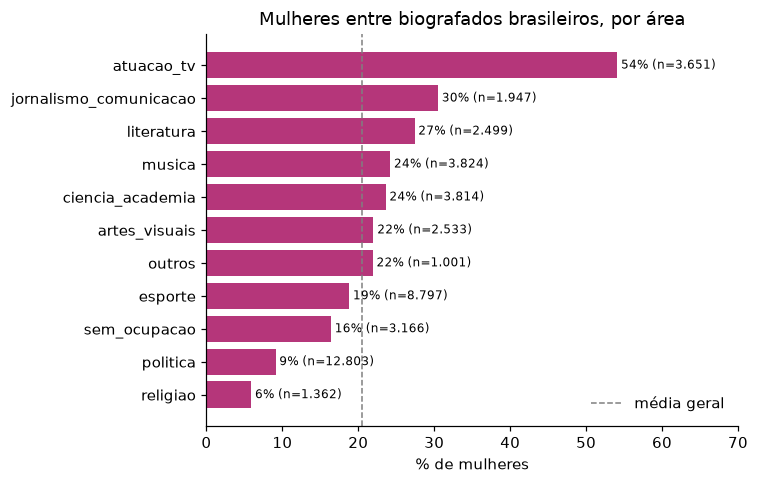

In [3]:
t = ap.por_area(df)
display(t)
t2 = t.sort_values('%F')
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(t2.index, t2['%F'], color=F_COR)
ax.axvline(100 * (df.sexo == 'F').sum() / df.sexo.isin(['F', 'M']).sum(), color='gray', ls='--', lw=1, label='média geral')
for y, (v, n) in enumerate(zip(t2['%F'], t2.total)): ax.text(v + 0.5, y, f'{v:.0f}% (n={n:,})'.replace(',', '.'), va='center', fontsize=8)
ax.set_xlabel('% de mulheres'); ax.set_xlim(0, 70); ax.legend(frameon=False)
ax.set_title('Mulheres entre biografados brasileiros, por área'); plt.tight_layout()

## % de mulheres por década de nascimento

sexo,F,M,total,%F
periodo,,,,
antes de 1800,38,677,715,5.3
1800–1899,347,5313,5660,6.1
1900–1949,2165,11544,13709,15.8
1950–1979,3096,9833,12929,23.9
1980+,2721,5297,8018,33.9


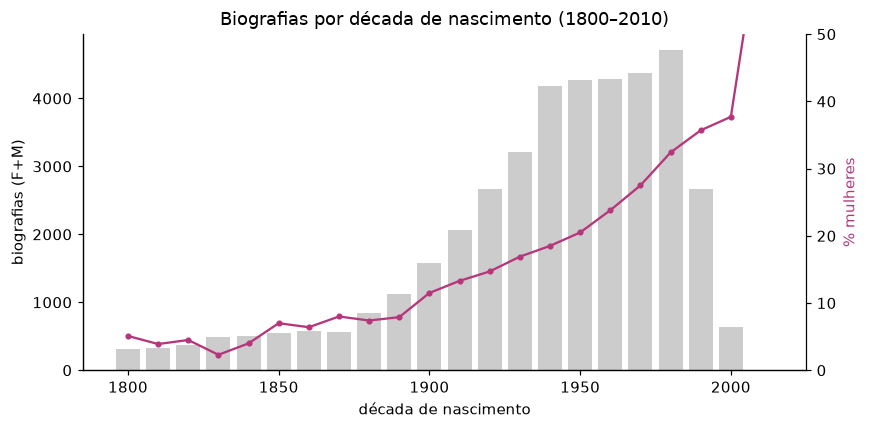

In [4]:
d = ap.por_decada(df)
fig, ax1 = plt.subplots(figsize=(8, 4))
ax1.bar(d.index, d.total, width=8, color='#cccccc', label='total de biografias')
ax1.set_ylabel('biografias (F+M)')
ax2 = ax1.twinx(); ax2.plot(d.index, d['%F'], color=F_COR, marker='o', ms=3, label='% mulheres')
ax2.set_ylabel('% mulheres', color=F_COR); ax2.set_ylim(0, 50); ax2.spines['right'].set_visible(True)
ax1.set_xlabel('década de nascimento'); ax1.set_title('Biografias por década de nascimento (1800–2010)')
plt.tight_layout()
ap.por_seculo(df)

## Cobertura dos metadados

In [5]:
ap.cobertura(df)

,% das pessoas,% entre F,% entre M
sem sexo (P21),0.4,NaN,NaN
sexo fora de F/M,0.4,NaN,NaN
sem ocupação (P106),7.3,5.6,7.3
ocupação sem área (outros),2.2,2.4,2.2
sem ano de nascimento (P569),9.9,9.8,9.6


## Ocupações mais frequentes

In [6]:
import pandas as pd
pd.concat({'F': ap.ocupacoes_mais_comuns(df, 'F').reset_index(), 'M': ap.ocupacoes_mais_comuns(df, 'M').reset_index()}, axis=1)

F                              M       
                  ocupacoes     n                ocupacoes      n
0                      ator  1770                 político  10455
1                  escritor   932              futebolista   4865
2                  político   918                 escritor   2780
3                    cantor   678               jornalista   2269
4                jornalista   653                     ator   1838
5                    modelo   576              advogado(a)   1447
6   ator/atriz de televisão   419               compositor   1357
7   professor universitário   341           padre católico   1086
8       jogador(a) de vôlei   297                   cantor   1012
9      ator/atriz de cinema   295                   médico    976
10              futebolista   279                   músico    971
11               compositor   251                    poeta    960
12                    poeta   235           bispo católico    937
13                professor   210  professor universitário    920
14     diretor(a) de cinema   182     treinador de futebol    899

## Observações

- O critério depende do Wikidata. Quem não tem P27=Q155 fica de fora, e imigrantes naturalizados entram.
- O sexo vem de P21. Os poucos casos fora de F/M são reportados, mas não entram nas comparações binárias.
- Esporte e política juntos são mais de 40% da população e quase todos homens. As análises de texto devem estratificar por área.
- A data de criação do artigo na pt.wiki não está no Wikidata. Vou buscá-la na etapa de coleta de texto, pela API (`prop=revisions&rvdir=newer`).